# Reproducing Figure 1: random labels and random inputs

Zhang et al., *Understanding deep learning requires rethinking generalization* (ICLR 2017). Panel (a) compares five Inception conditions. Panels (b,c) compare Inception, AlexNet, and a one-hidden-layer MLP at 11 label-corruption probabilities. With seed 42, the plans contain **36 unique runs** because the Inception endpoints are shared.

The earlier clean-baseline experiment remains separate. This expanded implementation resets training-order seeds at each epoch and evaluates the whole training set each epoch; its clean baseline is rerun for a consistent comparison and a measured convergence denominator.


## 1. Experimental settings

| Setting | Value |
|---|---|
| Data | CIFAR-10: 50,000 training / 10,000 test images |
| Preprocessing | Center crop 28 × 28; divide by 255; apply input condition; per-image standardization |
| Seed / batch size / initial budget | 42 / 128 / 64 epochs (25,024 updates) |
| Optimizer | SGD, momentum 0.9, weight decay 0 |
| Initial learning rate | Inception 0.1; AlexNet and MLP 0.01 |
| Learning-rate schedule | Multiply by 0.95 after each epoch through epoch 64; AlexNet/MLP continuation holds the next learning rate fixed |
| Loss | Softmax cross-entropy on raw logits; no label smoothing |
| Explicit regularization | No augmentation, dropout, or weight decay |
| Fit criterion, panel (b) | First epoch-end evaluation with zero errors over the entire training set |

Seed, batch size, budget, initialization, padding, BN/LRN details, permutation granularity, and smoothing/convergence rules are reconstruction choices rather than fully specified paper parameters. All models use Xavier-uniform initialization. Inception uses shift-only BN (epsilon 0.001, PyTorch momentum 0.1); AlexNet uses LRN size 9, alpha 0.001, beta 0.75, k=1. Runs not fitted within the budget are flagged, not treated as successful interpolation. Test accuracy does not determine stopping or hyperparameters.

AlexNet/MLP runs still unfitted at epoch 64 continue from their saved optimizer/model states at learning rate `0.01 * 0.95**64`, stopping at the first subsequent epoch with zero training errors (1,024-epoch safety cap). This learning-rate floor is a documented departure from the paper, not a recovered author setting. Inception and Figure 1(a) are unchanged. Decisions and unsuccessful trials are recorded separately in `reproduction_changes.md`.


In [1]:
import csv
import hashlib
import json
import math
import os
import platform
import random
import re
import uuid
import statistics
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

SEEDS = [42]
BATCH_SIZE = 128
EPOCHS = 64
P_VALUES = [round(p, 1) for p in np.linspace(0, 1, 11)]
NUM_WORKERS = 0  # Portable in notebook environments.
SMOKE_TEST = False
project_hint = Path(os.environ.get("ASSIGNMENT2_DIR", Path.cwd())).expanduser().resolve()
project_candidates = [
    candidate
    for ancestor in (project_hint, *project_hint.parents)
    for candidate in (ancestor, ancestor / "paper_1_generalization",
                      ancestor / "Assignemnt_2" / "paper_1_generalization")
]
PROJECT_DIR = next((candidate for candidate in project_candidates
                    if (candidate / "figure1_reproduction.ipynb").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open this notebook from its paper folder or set ASSIGNMENT2_DIR to the assignment root.")
DATA_DIR = next((ancestor / "data" for ancestor in (PROJECT_DIR, *PROJECT_DIR.parents)
                 if (ancestor / "data").is_dir()), PROJECT_DIR / "data")
RESULTS_DIR = (PROJECT_DIR / "results_figure1_reviewed" / ("smoke" if SMOKE_TEST else "full")).resolve()
ALLOW_DOWNLOAD = False
LOAD_DATA = True
RUN_FIGURE1A = True
RUN_SWEEP = True
BATCH_NAME = "seed42_full_v1"
CHECKPOINT_VERSION = 3
TRAIN_LIMIT = 256 if SMOKE_TEST else None
TEST_LIMIT = 128 if SMOKE_TEST else None
RUN_EPOCHS = 1 if SMOKE_TEST else EPOCHS
RUN_P_VALUES = [0.0, 1.0] if SMOKE_TEST else P_VALUES
IMPLEMENTATION_VERSION = "figure1-reviewed-v3"

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}; torch {torch.__version__}; torchvision {torchvision.__version__}")
print(f"Mode: {'SMOKE CHECK ONLY' if SMOKE_TEST else 'full CIFAR-10'}; seeds: {SEEDS}")
# Seeds aid repeatability; cross-hardware/framework bitwise equality is not guaranteed.

print(f"Working directory: {Path.cwd().resolve()}")
print(f"Project directory: {PROJECT_DIR}")
print(f"Data directory:    {DATA_DIR}")
print(f"Results directory: {RESULTS_DIR}")
print(f"Downloads enabled: {ALLOW_DOWNLOAD}")


Device: cuda; torch 2.6.0+cu124; torchvision 0.21.0+cu124
Mode: full CIFAR-10; seeds: [42]
Working directory: /array/katebej/assignment2_generalization_20261022
Project directory: /array/katebej/assignment2_generalization_20261022
Data directory:    /array/katebej/assignment2_generalization_20261022/data
Results directory: /array/katebej/assignment2_generalization_20261022/results_figure1_reviewed/full
Downloads enabled: False


## 2. Data and Gaussian statistics

Data are loaded from the existing CIFAR-10 directory without downloads. Gaussian parameters are a global mean and population variance calculated only from cropped, scaled training images, before per-image standardization. Noise is multiplied by the standard deviation, not the variance; generated values are not clipped or converted to uint8. Global versus per-channel moments and this preprocessing order are documented reconstruction choices.


In [2]:
def training_pixel_statistics(raw_images, limit=None, chunk_size=256):
    images = raw_images if limit is None else raw_images[:limit]
    total, total_square, count = 0.0, 0.0, 0
    for start in range(0, len(images), chunk_size):
        crop = images[start:start + chunk_size, 2:30, 2:30, :].astype(np.float64) / 255.0
        total += float(crop.sum())
        total_square += float(np.square(crop).sum())
        count += crop.size
    mean = total / count
    variance = max(total_square / count - mean * mean, 0.0)
    return {"mean": mean, "variance": variance, "std": math.sqrt(variance),
            "training_images": len(images), "scalar_values": count}


def load_cifar10_data(data_dir=None, allow_download=None):
    root = Path(data_dir if data_dir is not None else DATA_DIR).expanduser().resolve()
    download = ALLOW_DOWNLOAD if allow_download is None else bool(allow_download)
    print(f"Using CIFAR-10 root: {root}")
    print(f"Expected extracted folder: {root / 'cifar-10-batches-py'}")
    if not root.is_dir() and not download:
        raise FileNotFoundError(f"Data directory does not exist: {root}. Correct DATA_DIR; automatic downloads are disabled.")
    try:
        raw_train = datasets.CIFAR10(str(root), train=True, download=download)
        raw_test = datasets.CIFAR10(str(root), train=False, download=download)
    except RuntimeError as error:
        if not download:
            raise RuntimeError(f"CIFAR-10 was not found or failed its integrity check under {root}. "
                               "Reuse the existing extracted dataset at the configured location; no download was attempted.") from error
        raise
    assert len(raw_train) == 50_000 and len(raw_test) == 10_000
    pixel_stats = training_pixel_statistics(raw_train.data, TRAIN_LIMIT)
    print(json.dumps(pixel_stats, indent=2))
    return {"raw_train": raw_train, "raw_test": raw_test, "pixel_stats": pixel_stats,
            "statistics_limit": TRAIN_LIMIT, "data_root": str(root), "dataset_name": "CIFAR10"}


data_bundle = load_cifar10_data() if LOAD_DATA else None
if data_bundle is None:
    print("Data loading skipped. Call data_bundle = load_cifar10_data() before training/evaluation.")


Using CIFAR-10 root: /array/katebej/assignment2_generalization_20261022/data
Expected extracted folder: /array/katebej/assignment2_generalization_20261022/data/cifar-10-batches-py


{
  "mean": 0.4677336668000532,
  "variance": 0.06106332873577541,
  "std": 0.2471099527250479,
  "training_images": 50000,
  "scalar_values": 117600000
}


## 3. Fixed experimental datasets

| Condition | Inputs | Training labels | Test treatment |
|---|---|---|---|
| True labels | Original images | Original | Original images and labels |
| Random / partial labels | Original images | Independently resampled with probability p, uniformly among 10 classes | Original images and labels |
| Shuffled pixels | One shared permutation | Original | Same permutation, original labels |
| Random pixels | A different fixed permutation per image | Original | Independent fixed test permutations, original labels |
| Gaussian | A fixed Gaussian image per index | Original | Independent Gaussian test inputs, original labels |

Permutations operate on the 3 × 28 × 28 scalar channel values. The paper does not specify scalar values versus RGB triplets. Per-image randomness is determined by seed, condition, split, and index and remains fixed across epochs. Training order changes without changing these input-label pairs. At corruption probability p, approximately 0.9p of labels actually change because resampling can retain the original class. Nested corruption masks across p are an explicit comparison choice.


In [3]:
def per_image_standardize(image):
    denominator = image.std(unbiased=False).clamp_min(1.0 / math.sqrt(image.numel()))
    return (image - image.mean()) / denominator


class ExperimentDataset(Dataset):
    def __init__(self, raw, condition, p, seed, split, stats, limit=None):
        if condition not in {"labels", "shuffled_pixels", "random_pixels", "gaussian"}:
            raise ValueError(f"Unknown condition: {condition}")
        if not 0 <= p <= 1 or split not in {"train", "test"}:
            raise ValueError("Invalid p or split")
        if condition != "labels" and p != 0:
            raise ValueError("Pixel conditions retain original labels; use p=0.")
        self.data = raw.data if limit is None else raw.data[:limit]
        self.original_targets = np.asarray(raw.targets[:len(self.data)], dtype=np.int64).copy()
        self.targets = self.original_targets.copy()
        self.condition, self.p, self.seed, self.split = condition, p, int(seed), split
        self.stats = stats
        self.corruption_mask = np.zeros(len(self.data), dtype=bool)

        if condition == "labels" and split == "train":
            rng = np.random.default_rng(seed)
            self.corruption_mask = rng.random(len(self.data)) < p
            replacements = rng.integers(0, 10, size=len(self.data), dtype=np.int64)
            self.targets[self.corruption_mask] = replacements[self.corruption_mask]

        generator = torch.Generator().manual_seed(seed)
        self.shared_permutation = torch.randperm(3 * 28 * 28, generator=generator)

    def __len__(self):
        return len(self.data)

    def image_generator(self, index):
        # Distinct, repeatable streams; test index 0 never reuses train index 0 noise.
        condition_code = {"labels": 0, "shuffled_pixels": 1, "random_pixels": 2, "gaussian": 3}[self.condition]
        split_code = 0 if self.split == "train" else 1
        derived_seed = self.seed + condition_code * 1_000_000_000 + split_code * 10_000_000 + int(index)
        return torch.Generator().manual_seed(derived_seed)

    def unstandardized_image(self, index):
        if self.condition == "gaussian":
            return (torch.randn(3, 28, 28, generator=self.image_generator(index))
                    * self.stats["std"] + self.stats["mean"])
        crop = self.data[index, 2:30, 2:30, :]
        image = torch.from_numpy(crop.copy()).permute(2, 0, 1).float().contiguous() / 255.0
        if self.condition == "shuffled_pixels":
            image = image.flatten()[self.shared_permutation].reshape(3, 28, 28)
        elif self.condition == "random_pixels":
            permutation = torch.randperm(image.numel(), generator=self.image_generator(index))
            image = image.flatten()[permutation].reshape(3, 28, 28)
        return image

    def __getitem__(self, index):
        return per_image_standardize(self.unstandardized_image(index)), int(self.targets[index])

    def corruption_summary(self):
        return {"resampled_fraction": float(self.corruption_mask.mean()),
                "changed_fraction": float((self.targets != self.original_targets).mean())}


## 4. Architectures

Small Inception retains the Figure 3 reconstruction and 1,649,402 trainable parameters. Small AlexNet has two 64-channel, 5 × 5 convolution/pooling/LRN stages, hidden layers of 384 and 192 units, and 10 outputs (1,387,786 parameters); its convolution widths are inferred from Table 1. MLP 1×512 has one 512-unit ReLU hidden layer (1,209,866 parameters). All models return raw logits.


In [4]:
class ShiftOnlyBatchNorm(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm = nn.BatchNorm2d(
            channels, eps=1e-3, momentum=0.1, affine=False
        )
        self.beta = nn.Parameter(torch.zeros(1, channels, 1, 1))

    def forward(self, x):
        return self.norm(x) + self.beta


class ConvBNReLU(nn.Sequential):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=None):
        if padding is None:
            padding = kernel_size // 2
        super().__init__(
            nn.Conv2d(in_channels, out_channels, kernel_size,
                      stride=stride, padding=padding, bias=False),
            ShiftOnlyBatchNorm(out_channels),
            nn.ReLU(),
        )


class InceptionBlock(nn.Module):
    def __init__(self, in_channels, channels_1x1, channels_3x3):
        super().__init__()
        self.branch1 = ConvBNReLU(in_channels, channels_1x1, 1)
        self.branch3 = ConvBNReLU(in_channels, channels_3x3, 3)

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch3(x)], dim=1)


def same_pad(x, kernel_size=3, stride=2, value=0.0):
    h, w = x.shape[-2:]
    pad_h = max((math.ceil(h / stride) - 1) * stride + kernel_size - h, 0)
    pad_w = max((math.ceil(w / stride) - 1) * stride + kernel_size - w, 0)
    padding = (pad_w // 2, pad_w - pad_w // 2,
               pad_h // 2, pad_h - pad_h // 2)
    return F.pad(x, padding, value=value)


class DownsampleBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = ConvBNReLU(in_channels, out_channels, 3, stride=2, padding=0)

    def forward(self, x):
        conv = self.conv(same_pad(x))
        pool = F.max_pool2d(same_pad(x, value=float("-inf")), 3, stride=2)
        return torch.cat([conv, pool], dim=1)


class SmallInception(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBNReLU(3, 96, 3),
            InceptionBlock(96, 32, 32),
            InceptionBlock(64, 32, 48),
            DownsampleBlock(80, 80),       # 160 channels, 14 x 14
            InceptionBlock(160, 112, 48),
            InceptionBlock(160, 96, 64),
            InceptionBlock(160, 80, 80),
            InceptionBlock(160, 48, 96),
            DownsampleBlock(144, 96),      # 240 channels, 7 x 7
            InceptionBlock(240, 176, 160),
            InceptionBlock(336, 176, 160),
        )
        self.classifier = nn.Linear(336, 10)
        self.apply(self.initialize)

    @staticmethod
    def initialize(module):
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3))  # Global mean pooling over 7 x 7.
        return self.classifier(x)  # Raw logits; no explicit softmax.


In [5]:
class SameMaxPool(nn.Module):
    def forward(self, x):
        return F.max_pool2d(same_pad(x, value=float("-inf")), 3, stride=2)


class SmallAlexNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 5, padding=2), nn.ReLU(), SameMaxPool(),
            nn.LocalResponseNorm(9, alpha=0.001, beta=0.75, k=1.0),
            nn.Conv2d(64, 64, 5, padding=2), nn.ReLU(), SameMaxPool(),
            nn.LocalResponseNorm(9, alpha=0.001, beta=0.75, k=1.0),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 384), nn.ReLU(),
            nn.Linear(384, 192), nn.ReLU(), nn.Linear(192, 10),
        )
        self.apply(SmallInception.initialize)

    def forward(self, x):
        return self.classifier(self.features(x))


class MLP512(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Flatten(), nn.Linear(3 * 28 * 28, 512),
                                    nn.ReLU(), nn.Linear(512, 10))
        self.apply(SmallInception.initialize)

    def forward(self, x):
        return self.layers(x)


MODEL_FACTORIES = {"inception": SmallInception, "alexnet": SmallAlexNet, "mlp512": MLP512}
LEARNING_RATES = {"inception": 0.1, "alexnet": 0.01, "mlp512": 0.01}
EXPECTED_PARAMETERS = {"inception": 1_649_402, "alexnet": 1_387_786, "mlp512": 1_209_866}

for name, factory in MODEL_FACTORIES.items():
    candidate = factory().eval()
    count = sum(p.numel() for p in candidate.parameters() if p.requires_grad)
    with torch.no_grad():
        assert candidate(torch.zeros(2, 3, 28, 28)).shape == (2, 10)
    assert count == EXPECTED_PARAMETERS[name]
    print(f"{name:10s} {count:,} trainable parameters")
del candidate


inception  1,649,402 trainable parameters
alexnet    1,387,786 trainable parameters
mlp512     1,209,866 trainable parameters


## 5. Experiment plans

Panel (a) has five Inception conditions. The label sweep uses p = 0, 0.1, …, 1 for all three architectures, with unmodified test labels. Its Inception p=0 and p=1 endpoints reuse this batch's panel (a) runs; other conditions initialize fresh model and optimizer states.


In [6]:
def experiment(architecture, condition="labels", p=0.0, seed=42):
    return {"architecture": architecture, "condition": condition, "p": float(p), "seed": int(seed)}

FIGURE1A_PLAN = []
SWEEP_PLAN = []
for seed in SEEDS:
    FIGURE1A_PLAN.extend([
        experiment("inception", "labels", 0, seed),
        experiment("inception", "labels", 1, seed),
        experiment("inception", "shuffled_pixels", 0, seed),
        experiment("inception", "random_pixels", 0, seed),
        experiment("inception", "gaussian", 0, seed),
    ])
    SWEEP_PLAN.extend(experiment(name, "labels", p, seed)
                      for name in MODEL_FACTORIES for p in RUN_P_VALUES)
unique_runs = {json.dumps(spec, sort_keys=True) for spec in FIGURE1A_PLAN + SWEEP_PLAN}
print(f"Panel (a): {len(FIGURE1A_PLAN)} runs; sweep: {len(SWEEP_PLAN)}; unique total: {len(unique_runs)}")

def condition_label(spec):
    if spec["condition"] == "labels":
        return "True labels" if spec["p"] == 0 else "Random labels" if spec["p"] == 1 else f"Labels p={spec['p']:g}"
    return {"shuffled_pixels": "Shuffled pixels", "random_pixels": "Random pixels", "gaussian": "Gaussian"}[spec["condition"]]


Panel (a): 5 runs; sweep: 33; unique total: 36


## 6. Training, evaluation, and checkpoints

Every run has separate configuration, loss history, epoch checkpoint, and completion summary files. Checkpoints atomically preserve model, optimizer, scheduler, progress, RNG states, and the training-loader generator at completed-epoch boundaries. Fresh IDs cannot overwrite earlier runs; completed results are loaded without training. Mid-epoch interruptions repeat the unfinished epoch.

Training order uses seed + zero-based epoch. Both the full training set and test set are evaluated after each epoch. Panel (b) uses the first epoch-end zero-training-error step relative to the architecture's clean baseline; runs without a measured fit remain missing. The supplied 64-epoch budget is preserved rather than extended using test results.


In [7]:
def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)


def capture_rng_states(train_loader):
    numpy_state = np.random.get_state()
    return {
        "python": random.getstate(),
        # Convert the NumPy array to plain data for weights_only=True loading.
        "numpy": {"algorithm": numpy_state[0], "keys": numpy_state[1].tolist(),
                  "position": numpy_state[2], "has_gauss": numpy_state[3],
                  "cached_gaussian": numpy_state[4]},
        "torch_cpu": torch.get_rng_state().clone(),
        "torch_cuda": [state.cpu().clone() for state in torch.cuda.get_rng_state_all()]
                      if torch.cuda.is_available() else None,
        "torch_mps": torch.mps.get_rng_state().cpu().clone()
                     if torch.backends.mps.is_available() else None,
        "train_loader_generator": train_loader.generator.get_state().clone(),
    }


def restore_rng_states(states, train_loader):
    required = {"python", "numpy", "torch_cpu", "torch_cuda", "torch_mps", "train_loader_generator"}
    if not required.issubset(states):
        raise ValueError("Checkpoint is missing RNG states; exact resume is unavailable.")
    if states["torch_cuda"] is not None:
        if not torch.cuda.is_available() or len(states["torch_cuda"]) != torch.cuda.device_count():
            raise RuntimeError("Resume requires the saved CUDA device configuration.")
    if states["torch_mps"] is not None and not torch.backends.mps.is_available():
        raise RuntimeError("Resume requires an available MPS device.")
    random.setstate(states["python"])
    value = states["numpy"]
    np.random.set_state((value["algorithm"], np.asarray(value["keys"], dtype=np.uint32),
                         value["position"], value["has_gauss"], value["cached_gaussian"]))
    torch.set_rng_state(states["torch_cpu"].cpu())
    if states["torch_cuda"] is not None:
        torch.cuda.set_rng_state_all([state.cpu() for state in states["torch_cuda"]])
    if states["torch_mps"] is not None:
        torch.mps.set_rng_state(states["torch_mps"].cpu())
    train_loader.generator.set_state(states["train_loader_generator"].cpu())


def read_checkpoint(directory):
    saved = torch.load(Path(directory) / "checkpoint.pt", map_location="cpu", weights_only=True)
    if saved.get("checkpoint_version") != CHECKPOINT_VERSION:
        raise ValueError("This checkpoint predates full RNG saving. It cannot be silently resumed as an exact continuation.")
    return saved


def register_completed_result(directory):
    """Register an already-saved result; never called by plotting or loading."""
    result = load_result(directory)
    directory = Path(result["directory"])
    registry_path = directory.parent / "registry.json"
    registry = json.loads(registry_path.read_text()) if registry_path.exists() else {}
    run_id = result["summary"]["run_id"]
    entry = {"directory": directory.name, "config": result["summary"]["config"],
             "epochs_completed": result["summary"]["epochs_completed"]}
    if run_id in registry and registry[run_id]["directory"] != directory.name:
        raise ValueError("Run ID is already registered to another directory.")
    registry[run_id] = entry
    atomic_json(registry_path, registry)


def load_result(directory):
    """Read one completed result; no training, registration, or file writes."""
    directory = Path(directory).expanduser().resolve()
    summary_path = directory / "summary.json"
    if not summary_path.is_file():
        raise FileNotFoundError(f"No completed result at {directory}. Use resume_experiment for an epoch checkpoint.")
    summary = json.loads(summary_path.read_text())
    if summary.get("status") != "completed":
        raise ValueError("Result is not a completed run from this notebook revision.")
    history = json.loads((directory / "history.json").read_text())
    if len(history["epochs"]) != summary["epochs_completed"]:
        raise ValueError("History and completion metadata disagree.")
    if not history["steps"] or history["steps"][-1] != summary["steps"]:
        raise ValueError("History and global step disagree.")
    return {"summary": summary, "history": history, "directory": str(directory)}


def load_completed_results(results_root=None):
    """Discover durable results even if a crash occurred before registry update."""
    root = Path(results_root if results_root is not None else RESULTS_DIR).expanduser().resolve()
    return [load_result(path.parent) for path in sorted(root.glob("*/summary.json"))]


def load_model_for_evaluation(directory, target_device=None):
    """Load completed weights only; do not create an optimizer or train."""
    result = load_result(directory)
    saved = read_checkpoint(result["directory"])
    if saved["completed_epoch"] != result["summary"]["epochs_completed"]:
        raise ValueError("Checkpoint and completed result disagree.")
    target = torch.device(target_device if target_device is not None else device)
    # Loading a model should not change the caller's CPU random stream.
    with torch.random.fork_rng(devices=[]):
        model = MODEL_FACTORIES[saved["config"]["architecture"]]()
    model.load_state_dict(saved["model_state_dict"])
    model.to(target).eval()
    return model, result


def experiment_datasets(config, bundle):
    if bundle is None:
        raise ValueError("Call load_cifar10_data() first for fresh or interrupted training.")
    if bundle["dataset_name"] != config["dataset_name"]:
        raise ValueError("Dataset identity differs from the checkpoint.")
    common = dict(condition=config["condition"], p=config["p"], seed=config["seed"],
                  stats=config["pixel_statistics"])
    train = ExperimentDataset(bundle["raw_train"], split="train", limit=config["train_limit"], **common)
    test = ExperimentDataset(bundle["raw_test"], split="test", limit=config["test_limit"], **common)
    if len(train) != config["train_count"] or len(test) != config["test_count"]:
        raise ValueError("Dataset sizes differ from the saved experiment.")
    return train, test


def experiment_loaders(config, bundle, target_device=None):
    target = torch.device(target_device if target_device is not None else device)
    train, test = experiment_datasets(config, bundle)
    options = dict(batch_size=config["batch_size"], num_workers=config["num_workers"],
                   pin_memory=(target.type == "cuda"))
    generator = torch.Generator().manual_seed(config["seed"])
    train_loader = DataLoader(train, shuffle=True, generator=generator, **options)
    # These iterators consume the global CPU PyTorch stream, saved in the checkpoint.
    train_eval = DataLoader(train, shuffle=False, **options)
    test_loader = DataLoader(test, shuffle=False, **options)
    return train_loader, train_eval, test_loader


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    criterion = criterion if criterion is not None else nn.CrossEntropyLoss()
    target = next(model.parameters()).device
    was_training = model.training
    model.eval()
    loss_sum, errors, count = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(target), labels.to(target)
        logits = model(images)
        size = labels.size(0)
        loss_sum += criterion(logits, labels).item() * size
        errors += (logits.argmax(1) != labels).sum().item()
        count += size
    model.train(was_training)
    return {"loss": loss_sum / count, "error": errors / count,
            "accuracy": 1.0 - errors / count, "errors": errors, "count": count}


def run_configuration(spec, bundle, epochs):
    if bundle["statistics_limit"] != TRAIN_LIMIT:
        raise ValueError("TRAIN_LIMIT changed after data loading; reload the data bundle.")
    return {**spec, "implementation": IMPLEMENTATION_VERSION, "epochs": int(epochs),
            "dataset_name": bundle["dataset_name"], "data_root": bundle["data_root"],
            "smoke_test": SMOKE_TEST, "train_limit": TRAIN_LIMIT, "test_limit": TEST_LIMIT,
            "train_count": len(bundle["raw_train"].data[:TRAIN_LIMIT]),
            "test_count": len(bundle["raw_test"].data[:TEST_LIMIT]),
            "batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
            "lr": LEARNING_RATES[spec["architecture"]], "momentum": 0.9,
            "lr_decay_per_epoch": 0.95, "weight_decay": 0.0,
            "pixel_statistics": bundle["pixel_stats"], "permutation": "flattened_scalar_channel_values",
            "order": "crop_scale_corrupt_per_image_standardize", "gaussian_clipping": False,
            "initialization": "xavier_uniform", "padding": "tensorflow_same",
            "inception_bn": {"scale": False, "eps": 0.001, "pytorch_momentum": 0.1},
            "alexnet_lrn": {"size": 9, "alpha": 0.001, "beta": 0.75, "k": 1.0},
            "shuffle_rule": "seed_plus_zero_based_epoch_prepared_before_checkpoint",
            "fit_rule": "zero_train_eval_errors_checked_each_epoch",
            "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
            "numpy": str(np.__version__), "python": platform.python_version(), "device": str(device)}


def build_training_components(config, bundle):
    loaders = experiment_loaders(config, bundle)
    model = MODEL_FACTORIES[config["architecture"]]().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=config["lr"],
                                momentum=config["momentum"], weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=config["lr_decay_per_epoch"])
    return model, optimizer, scheduler, loaders


def finish_result(directory, saved):
    """Publish a completed checkpoint as immutable result files and register it."""
    config, history = saved["config"], saved["history"]
    if saved["completed_epoch"] != config["epochs"]:
        raise ValueError("Cannot finalize an incomplete experiment.")
    final = history["epochs"][-1]
    summary = {"status": "completed", "run_id": saved["run_id"], "config": config,
               "epochs_completed": saved["completed_epoch"], "steps": saved["global_step"],
               "first_fit_step": saved["first_fit_step"], "final_fit": final["train"]["errors"] == 0,
               "train": final["train"], "test": final["test"],
               "generalization_gap": final["test"]["error"] - final["train"]["error"],
               "corruption": saved["corruption"], "parameters": saved["parameters"]}
    atomic_json(directory / "history.json", history)
    atomic_json(directory / "summary.json", summary)
    register_completed_result(directory)
    return load_result(directory)


def train_remaining(directory, config, run_id, components, saved=None, pause_after_epoch=None):
    model, optimizer, scheduler, loaders = components
    train_loader, train_eval, test_loader = loaders
    criterion = nn.CrossEntropyLoss()
    history = saved["history"] if saved else {"steps": [], "batch_loss": [], "batch_size": [], "epochs": []}
    completed = saved["completed_epoch"] if saved else 0
    step = saved["global_step"] if saved else 0
    first_fit_step = saved["first_fit_step"] if saved else None
    for epoch in range(completed, config["epochs"]):
        # The generator is already ready for this epoch, from fresh setup or checkpoint.
        model.train()
        online_loss, online_errors, count = 0.0, 0, 0
        lr, started = optimizer.param_groups[0]["lr"], time.perf_counter()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss at global step {step + 1}")
            loss.backward()
            optimizer.step()
            size, value = labels.size(0), loss.item()
            step += 1
            history["steps"].append(step)
            history["batch_loss"].append(value)
            history["batch_size"].append(size)
            online_loss += value * size
            online_errors += (logits.argmax(1) != labels).sum().item()
            count += size
        train_metrics = evaluate(model, train_eval, criterion)
        test_metrics = evaluate(model, test_loader, criterion)
        if train_metrics["errors"] == 0 and first_fit_step is None:
            first_fit_step = step
        history["epochs"].append({"epoch": epoch + 1, "step": step, "lr": lr,
            "online_train_loss": online_loss / count, "online_train_accuracy": 1 - online_errors / count,
            "train": train_metrics, "test": test_metrics,
            "epoch_seconds_including_evaluation": time.perf_counter() - started})
        scheduler.step()
        # Preserve the existing seed+epoch order, but save the next epoch's ready state.
        # Resume does not reseed this generator or reset any progress counters.
        train_loader.generator.manual_seed(config["seed"] + epoch + 1)
        saved = {"checkpoint_version": CHECKPOINT_VERSION, "run_id": run_id, "config": config,
                 "model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
                 "scheduler_state_dict": scheduler.state_dict(), "completed_epoch": epoch + 1,
                 "global_step": step, "history": history, "first_fit_step": first_fit_step,
                 "rng_states": capture_rng_states(train_loader), "model_training": model.training,
                 "corruption": train_loader.dataset.corruption_summary(),
                 "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad)}
        temporary = directory / "checkpoint.tmp"
        torch.save(saved, temporary)
        temporary.replace(directory / "checkpoint.pt")
        atomic_json(directory / "history.json", history)
        print(f"{run_id}: epoch {epoch+1}/{config['epochs']}, step {step}, "
              f"loss {online_loss/count:.4f}, train {train_metrics['accuracy']:.2%}, test {test_metrics['accuracy']:.2%}")
        if pause_after_epoch is not None and epoch + 1 >= pause_after_epoch and epoch + 1 < config["epochs"]:
            return {"status": "paused", "directory": str(directory), "completed_epoch": epoch + 1,
                    "global_step": step}
    return finish_result(directory, saved)


def start_experiment(spec, bundle, run_id=None, epochs=None, results_root=None, pause_after_epoch=None):
    """Fresh model/optimizer only. Never overwrite or silently resume an existing run."""
    if bundle is None:
        raise ValueError("Load the data bundle before starting training.")
    epochs = RUN_EPOCHS if epochs is None else epochs
    if not isinstance(epochs, int) or epochs < 1:
        raise ValueError("epochs must be a positive integer")
    config = run_configuration(spec, bundle, epochs)
    run_id = run_id or f"{spec['architecture']}_{spec['condition']}_p{spec['p']:g}_seed{spec['seed']}_{uuid.uuid4().hex[:8]}"
    if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*", run_id):
        raise ValueError("Use a simple run ID containing letters, numbers, underscores, dots, or hyphens.")
    root = Path(results_root if results_root is not None else RESULTS_DIR).expanduser().resolve()
    root.mkdir(parents=True, exist_ok=True)
    directory = root / run_id
    directory.mkdir(exist_ok=False)  # Refuse replacement, including completed baselines.
    atomic_json(directory / "config.json", config)
    seed_everything(spec["seed"])
    components = build_training_components(config, bundle)
    return train_remaining(directory, config, run_id, components, pause_after_epoch=pause_after_epoch)


def resume_experiment(directory, bundle=None, pause_after_epoch=None):
    """Restore state and continue to the SAVED epoch budget; completed runs only load."""
    directory = Path(directory).expanduser().resolve()
    if (directory / "summary.json").exists():
        print(f"Already completed; loading without training: {directory.name}")
        return load_result(directory)
    saved = read_checkpoint(directory)
    config = saved["config"]
    if "continuation" in config:
        raise ValueError("Use continue_until_fit with the parent run for a continuation checkpoint.")
    if saved["completed_epoch"] == config["epochs"]:
        # Recover a crash after the last checkpoint but before final registration.
        return finish_result(directory, saved)
    if config["implementation"] != IMPLEMENTATION_VERSION:
        raise ValueError("Training implementation differs from the saved checkpoint.")
    for key, current in [("device", str(device)), ("torch", str(torch.__version__)),
                         ("torchvision", str(torchvision.__version__)), ("numpy", str(np.__version__))]:
        if config[key] != current:
            raise RuntimeError(f"Exact resume expects saved {key}={config[key]}; current value is {current}.")
    components = build_training_components(config, bundle)
    model, optimizer, scheduler, loaders = components
    model.load_state_dict(saved["model_state_dict"])
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    scheduler.load_state_dict(saved["scheduler_state_dict"])
    model.train(saved["model_training"])
    # Restore LAST: constructing models/optimizers/loaders may consume random numbers.
    restore_rng_states(saved["rng_states"], loaders[0])
    print(f"Resuming after epoch {saved['completed_epoch']}, global step {saved['global_step']}")
    return train_remaining(directory, config, saved["run_id"], components, saved, pause_after_epoch)


def run_plan(plan, bundle, batch_name, results_root=None):
    """Continue an explicitly named batch: load completed, resume paused, start missing."""
    if not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.-]*", batch_name):
        raise ValueError("Use a simple batch name without path separators.")
    root = Path(results_root if results_root is not None else RESULTS_DIR).expanduser().resolve()
    results = []
    for spec in plan:
        run_id = f"{batch_name}_{spec['architecture']}_{spec['condition']}_p{spec['p']:g}_seed{spec['seed']}"
        directory = root / run_id
        if directory.exists():
            config = json.loads((directory / "config.json").read_text())
            if any(config[key] != value for key, value in spec.items()):
                raise ValueError("Existing batch run has a different experiment specification.")
            expected = run_configuration(spec, bundle, RUN_EPOCHS)
            keys = ["implementation", "epochs", "batch_size", "num_workers", "train_limit", "test_limit",
                    "lr", "smoke_test", "dataset_name", "pixel_statistics"]
            if any(config[key] != expected[key] for key in keys):
                raise ValueError("Batch settings changed; choose a fresh BATCH_NAME instead of mixing budgets/settings.")
            results.append(resume_experiment(directory, bundle))
        else:
            results.append(start_experiment(spec, bundle, run_id=run_id, results_root=root))
    return results


In [8]:
CONTINUATION_VERSION = "figure1-convergence-v1"
CONTINUATION_MAX_EPOCHS = 1024
CONTINUATION_ROOT = RESULTS_DIR.parent / "convergence"
IMAGE_CACHE = {}


class CachedLabelLoader:
    def __init__(self, original, images):
        self.dataset = original.dataset
        self.generator = original.generator
        self.images = images
        self.targets = torch.as_tensor(self.dataset.targets, device=images.device)
        self.indices = DataLoader(
            range(len(self.dataset)), batch_size=original.batch_size,
            shuffle=isinstance(original.sampler, torch.utils.data.RandomSampler),
            generator=self.generator, num_workers=0,
        )

    def __iter__(self):
        for indices in self.indices:
            indices = indices.to(self.images.device)
            yield self.images[indices], self.targets[indices]

    def __len__(self):
        return len(self.indices)


def continuation_components(saved, bundle, use_cache=True):
    config = saved["config"]
    if config["condition"] != "labels" or config["architecture"] == "inception":
        raise ValueError("Only the AlexNet/MLP label sweeps are continued.")
    for key, current in [("device", str(device)), ("torch", str(torch.__version__)),
                         ("torchvision", str(torchvision.__version__)), ("numpy", str(np.__version__))]:
        if config[key] != current:
            raise RuntimeError(f"Continuation requires saved {key}={config[key]}, not {current}.")
    model, optimizer, scheduler, original_loaders = build_training_components(config, bundle)
    loaders = []
    for loader in original_loaders:
        if use_cache:
            key = (bundle["data_root"], loader.dataset.split, len(loader.dataset), str(device))
            if key not in IMAGE_CACHE:
                IMAGE_CACHE[key] = torch.stack(
                    [loader.dataset[index][0] for index in range(len(loader.dataset))]
                ).to(device)
            loader = CachedLabelLoader(loader, IMAGE_CACHE[key])
        loaders.append(loader)
    model.load_state_dict(saved["model_state_dict"])
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    scheduler.load_state_dict(saved["scheduler_state_dict"])
    model.train(saved["model_training"])
    restore_rng_states(saved["rng_states"], loaders[0])
    return model, optimizer, scheduler, tuple(loaders)


def continue_until_fit(source_directory, bundle, max_epochs=None, pause_after_epoch=None):
    source = load_result(source_directory)
    if source["summary"]["final_fit"]:
        return source
    max_epochs = CONTINUATION_MAX_EPOCHS if max_epochs is None else max_epochs
    source_checkpoint = Path(source["directory"]) / "checkpoint.pt"
    source_hash = hashlib.sha256(source_checkpoint.read_bytes()).hexdigest()
    source_config = source["summary"]["config"]
    if source_config["smoke_test"] or source_config["epochs"] != 64:
        raise ValueError("Continuation expects the original full-data, 64-epoch experiment.")
    floor = source_config["lr"] * source_config["lr_decay_per_epoch"] ** 64
    protocol = {"version": CONTINUATION_VERSION, "parent_run_id": source["summary"]["run_id"],
                "parent_checkpoint_sha256": source_hash, "parent_epochs": 64,
                "lr_floor": floor, "max_epochs": max_epochs,
                "stop_rule": "first_zero_train_eval_errors_after_parent_checkpoint"}
    directory = CONTINUATION_ROOT / source["summary"]["run_id"]
    if (directory / "summary.json").exists():
        result = load_result(directory)
        if result["summary"]["config"]["continuation"] != protocol:
            raise ValueError("Completed continuation settings or parent checkpoint changed.")
        return result
    if (directory / "checkpoint.pt").exists():
        saved = read_checkpoint(directory)
        if saved["config"]["continuation"] != protocol:
            raise ValueError("Interrupted continuation settings or parent checkpoint changed.")
    else:
        saved = read_checkpoint(source["directory"])
        config = dict(saved["config"], epochs=max_epochs, continuation=protocol)
        saved["config"] = config
        directory.mkdir(parents=True, exist_ok=True)
        if (directory / "config.json").exists():
            existing_config = json.loads((directory / "config.json").read_text())
            if existing_config != config:
                raise ValueError("Existing continuation directory has a different configuration.")
        atomic_json(directory / "config.json", config)
    config = saved["config"]
    model, optimizer, scheduler, loaders = continuation_components(saved, bundle)
    train_loader, train_eval, test_loader = loaders
    history = saved["history"]
    step = saved["global_step"]
    first_fit_step = saved["first_fit_step"]
    already_fitted = saved["history"]["epochs"][-1]["train"]["errors"] == 0
    remaining_epochs = range(saved["completed_epoch"], max_epochs) if not already_fitted else []
    for epoch in remaining_epochs:
        model.train()
        online_loss, online_errors, count = 0.0, 0, 0
        started = time.perf_counter()
        for group in optimizer.param_groups:
            group["lr"] = max(group["lr"], floor)
        learning_rate = optimizer.param_groups[0]["lr"]
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite continuation loss at step {step + 1}")
            loss.backward()
            optimizer.step()
            size, value = labels.size(0), loss.item()
            step += 1
            history["steps"].append(step)
            history["batch_loss"].append(value)
            history["batch_size"].append(size)
            online_loss += value * size
            online_errors += (logits.argmax(1) != labels).sum().item()
            count += size
        train_metrics = evaluate(model, train_eval)
        test_metrics = evaluate(model, test_loader)
        if train_metrics["errors"] == 0 and first_fit_step is None:
            first_fit_step = step
        history["epochs"].append({"epoch": epoch + 1, "step": step, "lr": learning_rate,
                                 "online_train_loss": online_loss / count,
                                 "online_train_accuracy": 1 - online_errors / count,
                                 "train": train_metrics, "test": test_metrics,
                                 "epoch_seconds_including_evaluation": time.perf_counter() - started})
        scheduler.step()
        train_loader.generator.manual_seed(config["seed"] + epoch + 1)
        saved = {"checkpoint_version": CHECKPOINT_VERSION, "run_id": source["summary"]["run_id"],
                 "config": config, "model_state_dict": model.state_dict(),
                 "optimizer_state_dict": optimizer.state_dict(), "scheduler_state_dict": scheduler.state_dict(),
                 "completed_epoch": epoch + 1, "global_step": step, "history": history,
                 "first_fit_step": first_fit_step, "rng_states": capture_rng_states(train_loader),
                 "model_training": model.training, "corruption": source["summary"]["corruption"],
                 "parameters": source["summary"]["parameters"]}
        finished = train_metrics["errors"] == 0 or epoch + 1 == max_epochs
        paused = pause_after_epoch is not None and epoch + 1 >= pause_after_epoch
        if finished or paused or (epoch + 1) % 10 == 0:
            temporary = directory / "checkpoint.tmp"
            torch.save(saved, temporary)
            temporary.replace(directory / "checkpoint.pt")
            atomic_json(directory / "progress.json", {"epoch": epoch + 1, "step": step,
                                                       "train": train_metrics, "lr": learning_rate})
            print(f"{directory.name}: epoch {epoch + 1}, errors {train_metrics['errors']}, "
                  f"loss {train_metrics['loss']:.6f}, lr {learning_rate:.8g}", flush=True)
        if finished:
            break
        if paused:
            return {"status": "paused", "directory": str(directory), "epoch": epoch + 1}
    final = saved["history"]["epochs"][-1]
    summary = {"status": "completed", "run_id": saved["run_id"], "config": config,
               "epochs_completed": saved["completed_epoch"], "steps": saved["global_step"],
               "first_fit_step": saved["first_fit_step"], "final_fit": final["train"]["errors"] == 0,
               "train": final["train"], "test": final["test"],
               "generalization_gap": final["test"]["error"] - final["train"]["error"],
               "corruption": saved["corruption"], "parameters": saved["parameters"]}
    atomic_json(directory / "history.json", saved["history"])
    atomic_json(directory / "summary.json", summary)
    return load_result(directory)


def preferred_results(results):
    selected = []
    for result in results:
        directory = CONTINUATION_ROOT / result["summary"]["run_id"]
        if (directory / "summary.json").exists():
            continued = load_result(directory)
            parent_hash = hashlib.sha256((Path(result["directory"]) / "checkpoint.pt").read_bytes()).hexdigest()
            if continued["summary"]["config"]["continuation"]["parent_checkpoint_sha256"] != parent_hash:
                raise ValueError("Continuation no longer matches the source checkpoint.")
            if continued["summary"]["train"]["errors"] <= result["summary"]["train"]["errors"]:
                result = continued
        selected.append(result)
    return selected


## 7. Figure construction

Panel (a) uses sample-weighted averages over 100 updates, a choice not specified by the paper. Panel (b) shows relative steps to zero training error. Panel (c) uses test error, marks runs not fitted within the budget with crosses, and shows chance error 0.9. Result labels come from saved experimental metadata.


In [9]:
def averaged_curve(history, window=100):
    x, y = [], []
    for start in range(0, len(history["steps"]), window):
        stop = min(start + window, len(history["steps"]))
        x.append(history["steps"][stop - 1] / 1000)
        y.append(np.average(history["batch_loss"][start:stop],
                            weights=history["batch_size"][start:stop]))
    return x, y


def plot_figure1a(results, window=100):
    configs = [result["summary"]["config"] for result in results]
    keys = [(c["condition"], c["p"], c["seed"]) for c in configs]
    if len(keys) != len(set(keys)):
        raise ValueError("Select one run per condition/seed before plotting Figure 1(a).")
    if any(c["architecture"] != "inception" for c in configs):
        raise ValueError("Figure 1(a) uses Inception results only.")
    plot_seeds = {c["seed"] for c in configs}
    scopes = {c["smoke_test"] for c in configs}
    if len(scopes) > 1:
        raise ValueError("Select either smoke checks or full-data results, not both.")
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for result in results:
        spec = result["summary"]["config"]
        x, y = averaged_curve(result["history"], window)
        label = condition_label(spec) + (f" (seed {spec['seed']})" if len(plot_seeds) > 1 else "")
        ax.plot(x, y, label=label, linewidth=1.8, marker="." if len(x) < 3 else None)
    suffix = " - SMOKE CHECK ONLY" if scopes == {True} else ""
    ax.set(xlabel="Training steps (thousands)", ylabel="Mean training cross-entropy",
           title="Figure 1(a): Small Inception" + suffix, xlim=(0, None), ylim=(0, None))
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    return fig


In [10]:
def plot_sweep(results):
    keys = [(r["summary"]["config"]["architecture"], r["summary"]["config"]["seed"],
             r["summary"]["config"]["p"]) for r in results]
    if len(keys) != len(set(keys)):
        raise ValueError("Select one run per architecture/p/seed before plotting the sweep.")
    plot_seeds = sorted({r["summary"]["config"]["seed"] for r in results})
    scopes = {r["summary"]["config"]["smoke_test"] for r in results}
    if len(scopes) > 1:
        raise ValueError("Select either smoke checks or full-data results, not both.")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = {"inception": "black", "alexnet": "tab:green", "mlp512": "tab:blue"}
    not_fitted = []
    for name in MODEL_FACTORIES:
        for seed in plot_seeds:
            group = sorted([r["summary"] for r in results
                            if r["summary"]["config"]["architecture"] == name
                            and r["summary"]["config"]["seed"] == seed],
                           key=lambda s: s["config"]["p"])
            baseline = next((s for s in group if s["config"]["p"] == 0), None)
            base_fit = baseline["first_fit_step"] if baseline else None
            p_values, ratios, errors = [], [], []
            for summary in group:
                p = summary["config"]["p"]
                p_values.append(p)
                fit = summary["first_fit_step"]
                ratios.append(fit / base_fit if fit is not None and base_fit else np.nan)
                errors.append(summary["test"]["error"] if summary["final_fit"] else np.nan)
                if not summary["final_fit"]:
                    not_fitted.append((name, seed, p, summary["train"]["errors"]))
                    axes[1].scatter(p, summary["test"]["error"], marker="x", color=colors[name])
            label = name + (f" seed {seed}" if len(plot_seeds) > 1 else "")
            axes[0].plot(p_values, ratios, "o-", color=colors[name], label=label)
            axes[1].plot(p_values, errors, "o-", color=colors[name], label=label)
    axes[0].set(title="(b) Steps to zero training error / clean baseline",
                xlabel="Label resampling probability p", ylabel="Relative steps to fit")
    axes[1].set(title="(c) Test error after fitting" if not not_fitted else "(c) Test error; x = not fitted",
                xlabel="Label resampling probability p", ylabel="Test error", ylim=(0, 1))
    axes[1].axhline(0.9, color="tab:red", linestyle="--", linewidth=1, label="Chance error")
    for ax in axes:
        ax.set_xlim(0, 1)
        ax.grid(alpha=0.25)
        ax.legend()
    if scopes == {True}:
        fig.suptitle("SMOKE CHECK ONLY: not reproduction results")
    if any("continuation" in result["summary"]["config"] for result in results):
        fig.suptitle("AlexNet/MLP: learning-rate floor after epoch 64", fontsize=10)
    fig.tight_layout()
    if not_fitted:
        print("Unfitted runs (architecture, seed, p, training mistakes):", not_fitted)
    return fig


## 8. Result summaries

Per-run metrics include the actual label-change fraction, first-fit step, and final fitting status. Between-seed sample variance is unavailable with a single seed; it is not reported as zero. Duplicate runs at seed 42 do not constitute independent seeds.


In [11]:
def result_tables(results):
    unique = {result["directory"]: result for result in results}
    rows, groups = [], {}
    for result in unique.values():
        summary, config = result["summary"], result["summary"]["config"]
        key = (config["architecture"], config["condition"], config["p"])
        groups.setdefault(key, []).append(summary)
        rows.append({"architecture": key[0], "condition": key[1], "p": key[2], "seed": config["seed"],
                     "train_accuracy": summary["train"]["accuracy"], "test_accuracy": summary["test"]["accuracy"],
                     "train_errors": summary["train"]["errors"], "final_fit": summary["final_fit"],
                     "first_fit_step": summary["first_fit_step"], "epochs": summary["epochs_completed"],
                     "resampled_fraction": summary["corruption"]["resampled_fraction"],
                     "changed_fraction": summary["corruption"]["changed_fraction"]})
    aggregate = []
    for (architecture, condition, p), summaries in groups.items():
        seeds = [summary["config"]["seed"] for summary in summaries]
        if len(seeds) != len(set(seeds)):
            raise ValueError("Select one run per condition/seed before estimating between-seed variance.")
        scores = [summary["test"]["accuracy"] for summary in summaries]
        aggregate.append({"architecture": architecture, "condition": condition, "p": p,
                          "n_seeds": len(scores), "mean_test_accuracy": statistics.mean(scores),
                          "sample_variance_test_accuracy": statistics.variance(scores) if len(scores) > 1 else None,
                          "all_final_fitted": all(s["final_fit"] for s in summaries)})
    return rows, aggregate


def write_csv(path, rows):
    if rows:
        with Path(path).open("w", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)


## 9. Execute the full experiment

The two plans share their overlapping Inception endpoints. Checkpoints, histories, summaries, plots, and CSV tables are saved separately from the earlier baseline.


In [12]:
if RUN_FIGURE1A:
    if data_bundle is None:
        raise ValueError("Load data_bundle first.")
    figure1a_results = run_plan(FIGURE1A_PLAN, data_bundle, BATCH_NAME)
    figure1a_plot = plot_figure1a(figure1a_results, window=1 if SMOKE_TEST else 100)
    figure1a_plot.savefig(RESULTS_DIR / "figure1a.png", dpi=180)
    plt.close(figure1a_plot)
    print(f"Figure 1(a) saved: {RESULTS_DIR / 'figure1a.png'}")
else:
    print("Full Figure 1(a) training is disabled.")


In [13]:
if RUN_SWEEP:
    if data_bundle is None:
        raise ValueError("Load data_bundle first.")
    sweep_results = run_plan(SWEEP_PLAN, data_bundle, BATCH_NAME)
    sweep_results = [continue_until_fit(result["directory"], data_bundle)
                     if not result["summary"]["final_fit"] else result for result in sweep_results]
    sweep_plot = plot_sweep(sweep_results)
    sweep_plot.savefig(RESULTS_DIR / "figure1bc.png", dpi=180)
    plt.close(sweep_plot)
    print(f"Figures 1(b-c) saved: {RESULTS_DIR / 'figure1bc.png'}")
else:
    print("Full three-model sweep is disabled.")


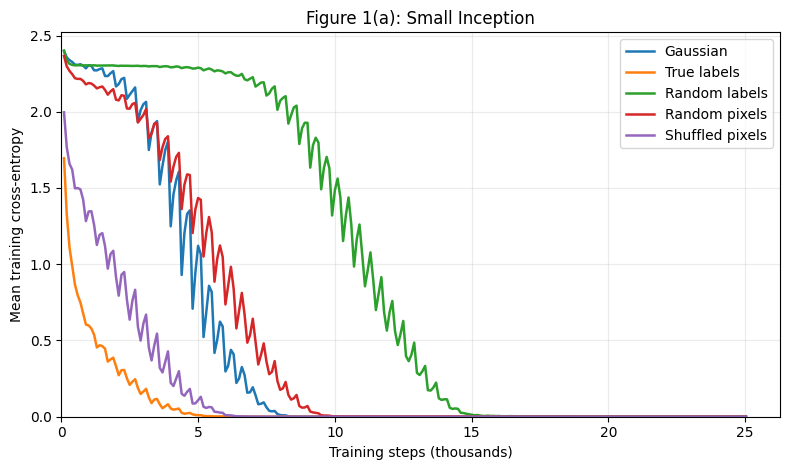

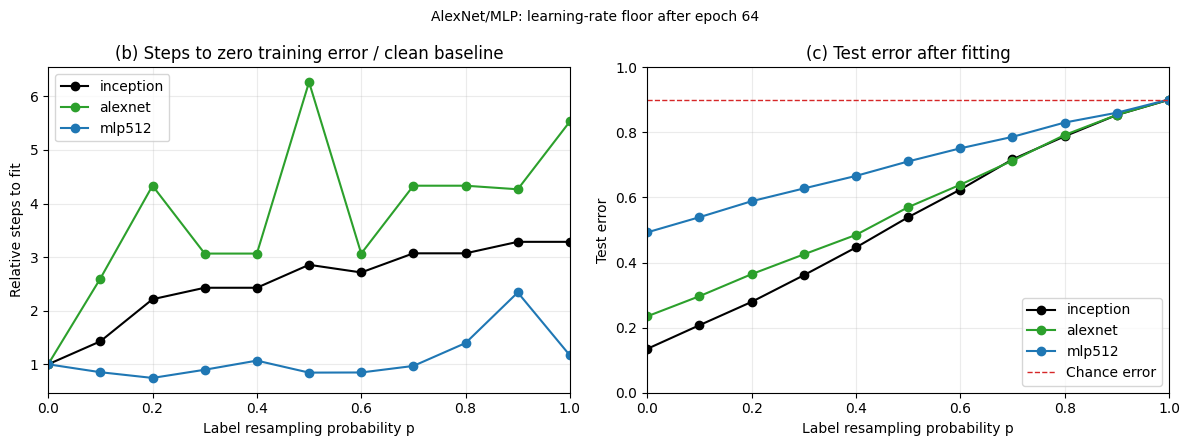

In [14]:
completed_results = load_completed_results(RESULTS_DIR)
SELECT_RUN_IDS = []
selected_results = [result for result in completed_results
                    if result["summary"]["run_id"].startswith(BATCH_NAME + "_")
                    and (not SELECT_RUN_IDS or result["summary"]["run_id"] in SELECT_RUN_IDS)]
selected_results = preferred_results(selected_results)
figure1a_results = [result for result in selected_results
                   if result["summary"]["config"]["architecture"] == "inception"
                   and (result["summary"]["config"]["condition"] != "labels"
                        or result["summary"]["config"]["p"] in (0, 1))]
sweep_results = [result for result in selected_results
                 if result["summary"]["config"]["condition"] == "labels"]
if figure1a_results:
    fig = plot_figure1a(figure1a_results, window=1 if SMOKE_TEST else 100)
    plt.show()
if sweep_results:
    fig = plot_sweep(sweep_results)
    plt.show()
if not completed_results:
    print(f"No completed results found in {RESULTS_DIR}. No training was started.")


In [15]:
rows, aggregates = result_tables(selected_results)
write_csv(RESULTS_DIR / "run_summary.csv", rows)
write_csv(RESULTS_DIR / "seed_summary.csv", aggregates)
not_fitted = [row for row in rows if not row["final_fit"]]
print(f"Completed unique runs: {len(rows)}")
print(f"Runs without zero final training error: {len(not_fitted)}")
print(f"Saved results: {RESULTS_DIR}")

assert len(rows) == 36 and not not_fitted, "The full sweep has not fitted every configuration."

for architecture in MODEL_FACTORIES:
    model_rows = [row for row in rows if row["architecture"] == architecture and row["condition"] == "labels"]
    assert len(model_rows) == 11 and all(row["first_fit_step"] is not None for row in model_rows)


Completed unique runs: 36
Runs without zero final training error: 0
Saved results: /array/katebej/assignment2_generalization_20261022/results_figure1_reviewed/full


## References and provenance

- Zhang et al. (2017), supplied PDF: Section 2.1, Figure 1, Table 1, Figure 3, and Appendix A. [Paper](https://arxiv.org/abs/1611.03530).
- Official PyTorch and TensorFlow documentation informed the original chat's API choices.

The supplied online-chat version discloses earlier access to the authors' repository landing page/README, including example commands and sample output, but reports no access to implementation files. This exposure remains disclosed; no authors' repository or reproduction implementation was consulted for this preparation. The supplied notebook was converted from pasted text and adapted with an IDE assistant for portable paths, the requested full-run flags, and saved plot/table exports. Architecture, corruption, loss, SGD, shuffle policy, and convergence definitions are unchanged from that supplied version.


## Verification

Jarvis checks passed using Python 3.10.12, PyTorch 2.6.0+cu124, and torchvision 0.21.0+cu124: all cells parse, all 36 configurations are planned, every architecture and corruption condition completes a synthetic CPU training check, completed runs reload without writes, existing runs cannot be overwritten, plots and CSV export work, and interrupted training matches uninterrupted CPU training exactly for all three architectures. These software checks do not establish full-data convergence, agreement with the paper, or bitwise CUDA resume equivalence.